In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from pathlib import Path
import seaborn as sns
from pathlib import Path
import sys
from utils import construct_path, read_feather_gcs, pq_to_xy



In [9]:
### LOAD DATA
DATASET = "malecns_09"
SUBSET_NAME = "optic"
DATA_PATH = (Path.cwd().parent/"connectome_data")
pin_data  = 'pin_data'
out_dir = Path("connectome_data/processed")
dataset_base = DATASET.split("_")[0]  # "malecns"


edgelist_path = (
        f"{DATA_PATH}/{dataset_base}/"
        f"{dataset_base}_{SUBSET_NAME}_{DATASET}_{SUBSET_NAME}_simple_edgelist.feather"
    )

synapses_path = (
        f"{DATA_PATH}/{dataset_base}/"
        f"{dataset_base}_{SUBSET_NAME}_{DATASET}_{SUBSET_NAME}_synapses.feather"
    )
pin_data_path = (
        f"{DATA_PATH}/{dataset_base}/")
print(f"Using subset: {SUBSET_NAME}")

meta_path = construct_path(str(DATA_PATH), DATASET, "meta")
print(f"Meta path: {meta_path}")
print(f"Edgelist path: {edgelist_path}")


##LOAD Nodes and edges
meta = read_feather_gcs(meta_path, gcs_fs=None)
meta["malecns_09_id"] = meta["malecns_09_id"].astype("int64")

nodes_df = meta.query("region == 'optic_lobe'").copy().reset_index(drop=True)
cols_to_keep= ['malecns_09_id', 'side', 'cell_type','neurotransmitter_predicted', 'neurotransmitter_score',
                'hex_1', 'hex_2',
                ]
nodes_df.rename(columns={"optic_lobe_hex_1": "hex_1",
                               "optic_lobe_hex_2": "hex_2"
                               }, inplace=True)
nodes_df = nodes_df[cols_to_keep].reset_index(drop=True)

edgelist = read_feather_gcs(edgelist_path, gcs_fs=None)
edgelist = edgelist[edgelist["count"] > 3].copy().reset_index(drop=True)


Using subset: optic
Meta path: /home/guardomayas/NUIN/sjbcs/male_cns_var/connectome_data/malecns/malecns_09_meta.feather
Edgelist path: /home/guardomayas/NUIN/sjbcs/male_cns_var/connectome_data/malecns/malecns_optic_malecns_09_optic_simple_edgelist.feather
Loaded 165,114 rows
Loaded 6,629,951 rows


In [3]:
## Add p q coordinates 
nodes_df["hex_1"] = pd.to_numeric(
    nodes_df["hex_1"], errors="coerce"
)
nodes_df["hex_2"] = pd.to_numeric(
    nodes_df["hex_2"], errors="coerce"
)
nodes_df["p"] = nodes_df["hex_1"] - 18
nodes_df["q"] = nodes_df["hex_2"] - 19
nodes_df.head()

,malecns_09_id,side,cell_type,neurotransmitter_predicted,neurotransmitter_score,hex_1,hex_2,p,q
0,11901,right,5thsLNv_LNd6,unclear,0.491188,NaN,NaN,NaN,NaN
1,12254,right,5thsLNv_LNd6,acetylcholine,0.531692,NaN,NaN,NaN,NaN
2,13531,left,5thsLNv_LNd6,acetylcholine,0.544733,NaN,NaN,NaN,NaN
3,14633,left,5thsLNv_LNd6,unclear,0.458165,NaN,NaN,NaN,NaN
4,15319,right,AOTU045,glutamate,0.804108,NaN,NaN,NaN,NaN


In [4]:
columnar_nodes = nodes_df.query(
    "hex_1.notna() and hex_2.notna()"
).copy().reset_index(drop=True)

print("Columnar cell types:")
print(columnar_nodes["cell_type"].unique())
# Optional: clean dtypes before saving
columnar_nodes["malecns_09_id"] = columnar_nodes["malecns_09_id"].astype("int64")
columnar_nodes["cell_type"] = columnar_nodes["cell_type"].astype("string")
columnar_nodes["side"] = columnar_nodes["side"].astype("string")
columnar_nodes.to_feather(out_dir / "columnar_nodes.feather")
columnar_nodes.head()

Columnar cell types:
['C2' 'C3' 'L1' 'L2' 'L3' 'L5' 'Mi1' 'Mi4' 'Mi9' 'T1' 'Tm1' 'Tm2' 'Tm20'
 'Tm4' 'Tm9']


,malecns_09_id,side,cell_type,neurotransmitter_predicted,neurotransmitter_score,hex_1,hex_2,p,q
0,100043,right,C2,gaba,0.528316,24.0,17.0,6.0,-2.0
1,100062,right,C2,unclear,0.398571,24.0,35.0,6.0,16.0
2,100134,right,C2,unclear,0.405942,22.0,31.0,4.0,12.0
3,100156,right,C2,unclear,0.467389,28.0,38.0,10.0,19.0
4,100229,right,C2,unclear,0.581083,27.0,13.0,9.0,-6.0


In [5]:
columnar_nodes

,malecns_09_id,side,cell_type,neurotransmitter_predicted,neurotransmitter_score,hex_1,hex_2,p,q
0,100043,right,C2,gaba,0.528316,24.0,17.0,6.0,-2.0
1,100062,right,C2,unclear,0.398571,24.0,35.0,6.0,16.0
2,100134,right,C2,unclear,0.405942,22.0,31.0,4.0,12.0
3,100156,right,C2,unclear,0.467389,28.0,38.0,10.0,19.0
4,100229,right,C2,unclear,0.581083,27.0,13.0,9.0,-6.0
...,...,...,...,...,...,...,...,...,...
23715,99591,left,Tm9,acetylcholine,0.974427,17.0,6.0,-1.0,-13.0
23716,99729,left,Tm9,acetylcholine,0.959740,12.0,13.0,-6.0,-6.0
23717,99798,right,Tm9,acetylcholine,0.959936,10.0,15.0,-8.0,-4.0
23718,99825,right,Tm9,acetylcholine,0.974427,10.0,17.0,-8.0,-2.0


## Infer and add columns to T4 T5

In [6]:
from scipy.optimize import linear_sum_assignment
import pandas as pd
import numpy as np

def assign_home_col_from_inputs(
    col_nodes,
    nodes_df,
    edgelist,
    input_types=("Mi1",),
    post_types=("T4a", "T4b", "T4c", "T4d"),
    id_col="malecns_09_id",
    count_col="count",
):
    if isinstance(input_types, str):
        input_types = (input_types,)

    # -------------------------
    # Input cells with known columns
    # -------------------------
    central_input_nodes = (
        col_nodes
        .query("cell_type in @input_types")
        .copy()
        .reset_index(drop=True)
    )

    central_input_nodes["column_id"] = (
        central_input_nodes["side"].astype(str)
        + "_"
        + central_input_nodes["hex_1"].astype("Int64").astype(str)
        + "_"
        + central_input_nodes["hex_2"].astype("Int64").astype(str)
    )

    central_cols = central_input_nodes[
        [
            id_col,
            "cell_type",
            "side",
            "hex_1",
            "hex_2",
            "p",
            "q",
            "column_id",
        ]
    ].rename(
        columns={
            id_col: "pre",
            "cell_type": "pre_type",
            "side": "pre_side",
        }
    )

    # -------------------------
    # Add pre/post type and side
    # -------------------------
    node_info = nodes_df[
        [id_col, "cell_type", "side"]
    ].copy()

    edges_typed = (
        edgelist
        .merge(
            node_info.rename(
                columns={
                    id_col: "pre",
                    "cell_type": "pre_type",
                    "side": "pre_side",
                }
            ),
            on="pre",
            how="left",
        )
        .merge(
            node_info.rename(
                columns={
                    id_col: "post",
                    "cell_type": "post_type",
                    "side": "post_side",
                }
            ),
            on="post",
            how="left",
        )
    )

    # Only same-side edges
    edges_typed = edges_typed[
        edges_typed["pre_side"].notna()
        & edges_typed["post_side"].notna()
        & (edges_typed["pre_side"] == edges_typed["post_side"])
    ].copy()

    central_T_edges = edges_typed[
        edges_typed["pre_type"].isin(input_types)
        & edges_typed["post_type"].isin(post_types)
    ].copy()

    central_T_edges = central_T_edges.merge(
        central_cols,
        on=["pre", "pre_type", "pre_side"],
        how="inner",
    )

    column_table = (
        central_input_nodes[
            ["column_id", "side", "hex_1", "hex_2", "p", "q"]
        ]
        .drop_duplicates("column_id")
        .reset_index(drop=True)
    )

    matched_parts = []

    # -------------------------
    # Match separately by side and post type
    # -------------------------
    for side in sorted(column_table["side"].dropna().unique()):
        side_columns = column_table.query("side == @side").copy()

        for post_type in post_types:
            sub = central_T_edges.query(
                "post_type == @post_type and pre_side == @side and post_side == @side"
            ).copy()

            if sub.empty:
                print(f"No edges found for {input_types} → {post_type} on side {side}")
                continue

            post_ids = (
                nodes_df.query("cell_type == @post_type and side == @side")[id_col]
                .drop_duplicates()
                .to_numpy()
            )

            col_ids = side_columns["column_id"].to_numpy()

            if len(post_ids) == 0 or len(col_ids) == 0:
                print(f"No posts or columns for {post_type} on side {side}")
                continue

            scores = (
                sub
                .groupby(["column_id", "post"], as_index=False)[count_col]
                .sum()
            )

            mat = pd.DataFrame(
                0.0,
                index=col_ids,
                columns=post_ids,
            )

            for _, row in scores.iterrows():
                col = row["column_id"]
                post = row["post"]

                if col in mat.index and post in mat.columns:
                    mat.loc[col, post] += row[count_col]

            cost = -mat.to_numpy()
            row_ind, col_ind = linear_sum_assignment(cost)

            matched = pd.DataFrame({
                "column_id": mat.index[row_ind],
                id_col: mat.columns[col_ind],
                count_col: mat.to_numpy()[row_ind, col_ind],
                "cell_type": post_type,
                "side": side,
                "input_types_used": ",".join(input_types),
            })

            matched = matched.query(f"{count_col} > 0").copy()

            matched = matched.merge(
                side_columns,
                on=["column_id", "side"],
                how="left",
            )

            matched_parts.append(matched)

    if len(matched_parts) == 0:
        return pd.DataFrame(
            columns=[id_col, "cell_type", "side", "hex_1", "hex_2", "p", "q"]
        )

    home_cols = pd.concat(matched_parts, ignore_index=True)

    home_cols = home_cols.drop(
        columns=["column_id", "input_types_used", count_col]
    )

    return home_cols

In [7]:
from scipy.optimize import linear_sum_assignment
import pandas as pd
import numpy as np


def assign_home_col_from_inputs_normalized(
    col_nodes,
    nodes_df,
    edgelist,
    input_types=("Mi1",),
    post_types=("T4a", "T4b", "T4c", "T4d"),
    id_col="malecns_09_id",
    count_col="count",
    min_raw_count=1,
    return_scores=False,
):
    """
    Assign existing column identities to T4/T5 neurons using maximum-weight matching.

    This version normalizes each input-column row by its total output to all
    postsynaptic neurons of a given post_type, analogous to:

        C_norm[i, j] = C[i, j] / sum_k C[i, k]

    where i is a known input column and j is a postsynaptic T4/T5 neuron.

    Parameters
    ----------
    col_nodes : pd.DataFrame
        Nodes with known column assignments. Must include:
        id_col, cell_type, side, hex_1, hex_2, p, q.

    nodes_df : pd.DataFrame
        Node metadata. Must include:
        id_col, cell_type, side.

    edgelist : pd.DataFrame
        Edge table. Must include:
        pre, post, count_col.

    input_types : tuple or str
        Known columnar input types used for assignment.
        Example: ("Mi1",) for T4, or ("Tm1", "Tm2") for T5.

    post_types : tuple
        Postsynaptic cell types to assign.
        Example: ("T4a", "T4b", "T4c", "T4d").

    min_raw_count : int or float
        Reject assignments with fewer than this many raw synapses.

    return_scores : bool
        If True, keep raw_count, normalized_score, and input_types_used
        in the returned table.

    Returns
    -------
    home_cols : pd.DataFrame
        Assigned home columns for post neurons.
    """

    if isinstance(input_types, str):
        input_types = (input_types,)

    # -------------------------
    # Input cells with known columns
    # -------------------------
    central_input_nodes = (
        col_nodes
        .query("cell_type in @input_types")
        .copy()
        .reset_index(drop=True)
    )

    central_input_nodes["column_id"] = (
        central_input_nodes["side"].astype(str)
        + "_"
        + central_input_nodes["hex_1"].astype("Int64").astype(str)
        + "_"
        + central_input_nodes["hex_2"].astype("Int64").astype(str)
    )

    central_cols = central_input_nodes[
        [
            id_col,
            "cell_type",
            "side",
            "hex_1",
            "hex_2",
            "p",
            "q",
            "column_id",
        ]
    ].rename(
        columns={
            id_col: "pre",
            "cell_type": "pre_type",
            "side": "pre_side",
        }
    )

    # -------------------------
    # Add pre/post type and side
    # -------------------------
    node_info = nodes_df[[id_col, "cell_type", "side"]].copy()

    edges_typed = (
        edgelist
        .merge(
            node_info.rename(
                columns={
                    id_col: "pre",
                    "cell_type": "pre_type",
                    "side": "pre_side",
                }
            ),
            on="pre",
            how="left",
        )
        .merge(
            node_info.rename(
                columns={
                    id_col: "post",
                    "cell_type": "post_type",
                    "side": "post_side",
                }
            ),
            on="post",
            how="left",
        )
    )

    # Only same-side edges
    edges_typed = edges_typed[
        edges_typed["pre_side"].notna()
        & edges_typed["post_side"].notna()
        & (edges_typed["pre_side"] == edges_typed["post_side"])
    ].copy()

    # Only known input type -> target T4/T5 type edges
    central_T_edges = edges_typed[
        edges_typed["pre_type"].isin(input_types)
        & edges_typed["post_type"].isin(post_types)
    ].copy()

    # Attach known column identity of the input neuron
    central_T_edges = central_T_edges.merge(
        central_cols,
        on=["pre", "pre_type", "pre_side"],
        how="inner",
    )

    column_table = (
        central_input_nodes[
            ["column_id", "side", "hex_1", "hex_2", "p", "q"]
        ]
        .drop_duplicates("column_id")
        .reset_index(drop=True)
    )

    matched_parts = []

    # -------------------------
    # Match separately by side and post type
    # -------------------------
    for side in sorted(column_table["side"].dropna().unique()):
        side_columns = column_table.query("side == @side").copy()

        for post_type in post_types:
            sub = central_T_edges.query(
                "post_type == @post_type and pre_side == @side and post_side == @side"
            ).copy()

            if sub.empty:
                print(f"No edges found for {input_types} → {post_type} on side {side}")
                continue

            post_ids = (
                nodes_df
                .query("cell_type == @post_type and side == @side")[id_col]
                .drop_duplicates()
                .to_numpy()
            )

            col_ids = side_columns["column_id"].to_numpy()

            if len(post_ids) == 0 or len(col_ids) == 0:
                print(f"No posts or columns for {post_type} on side {side}")
                continue

            # Raw connectivity matrix C[column, post]
            scores = (
                sub
                .groupby(["column_id", "post"], as_index=False)[count_col]
                .sum()
            )

            mat_raw = pd.DataFrame(
                0.0,
                index=col_ids,
                columns=post_ids,
            )

            for _, row in scores.iterrows():
                col = row["column_id"]
                post = row["post"]

                if col in mat_raw.index and post in mat_raw.columns:
                    mat_raw.loc[col, post] += row[count_col]

            # -------------------------
            # Row-normalize:
            # C_norm[i, j] = C[i, j] / sum_k C[i, k]
            # -------------------------
            row_sums = mat_raw.sum(axis=1)

            mat_norm = mat_raw.div(
                row_sums.replace(0, np.nan),
                axis=0,
            ).fillna(0.0)

            # Maximize normalized connectivity
            cost = -mat_norm.to_numpy()
            row_ind, col_ind = linear_sum_assignment(cost)

            matched = pd.DataFrame({
                "column_id": mat_norm.index[row_ind],
                id_col: mat_norm.columns[col_ind],
                "raw_count": mat_raw.to_numpy()[row_ind, col_ind],
                "normalized_score": mat_norm.to_numpy()[row_ind, col_ind],
                "cell_type": post_type,
                "side": side,
                "input_types_used": ",".join(input_types),
            })

            # Reject zero/very weak raw assignments
            matched = matched.query("raw_count >= @min_raw_count").copy()

            matched = matched.merge(
                side_columns,
                on=["column_id", "side"],
                how="left",
            )

            matched_parts.append(matched)

    if len(matched_parts) == 0:
        base_cols = [id_col, "cell_type", "side", "hex_1", "hex_2", "p", "q"]
        if return_scores:
            base_cols += ["raw_count", "normalized_score", "input_types_used"]
        return pd.DataFrame(columns=base_cols)

    home_cols = pd.concat(matched_parts, ignore_index=True)

    if not return_scores:
        home_cols = home_cols.drop(
            columns=["column_id", "input_types_used", "raw_count", "normalized_score"]
        )
    else:
        # Usually column_id is useful for debugging if returning scores
        home_cols = home_cols[
            [
                id_col,
                "cell_type",
                "side",
                "hex_1",
                "hex_2",
                "p",
                "q",
                "column_id",
                "raw_count",
                "normalized_score",
                "input_types_used",
            ]
        ]

    return home_cols

T4_cols = assign_home_col_from_inputs_normalized(
    col_nodes=columnar_nodes,
    nodes_df=nodes_df,
    edgelist=edgelist,
    input_types=("Mi1",),
    post_types=("T4a", "T4b", "T4c", "T4d"),
    id_col="malecns_09_id",
    count_col="count",
    min_raw_count=1,
    return_scores=True,
)

T5_cols = assign_home_col_from_inputs_normalized(
    col_nodes=columnar_nodes,
    nodes_df=nodes_df,
    edgelist=edgelist,
    input_types=("Tm1", "Tm2"),
    post_types=("T5a", "T5b", "T5c", "T5d"),
    id_col="malecns_09_id",
    count_col="count",
    min_raw_count=1,
    return_scores=True,
)

No edges found for ('Mi1',) → T4a on side left
No edges found for ('Mi1',) → T4b on side left
No edges found for ('Mi1',) → T4c on side left
No edges found for ('Mi1',) → T4d on side left
No edges found for ('Tm1', 'Tm2') → T5a on side left
No edges found for ('Tm1', 'Tm2') → T5b on side left
No edges found for ('Tm1', 'Tm2') → T5c on side left
No edges found for ('Tm1', 'Tm2') → T5d on side left


In [8]:
# T4_cols = assign_home_col_from_inputs(
#     col_nodes=columnar_nodes,
#     nodes_df=nodes_df,
#     edgelist=edgelist,
#     input_types=("Mi1",),
#     post_types=("T4a", "T4b", "T4c", "T4d"),
# )

In [9]:
T4_cols

,malecns_09_id,cell_type,side,hex_1,hex_2,p,q,column_id,raw_count,normalized_score,input_types_used
0,142157,T4a,right,1.0,10.0,-17.0,-9.0,right_1_10,18.0,0.782609,Mi1
1,135977,T4a,right,2.0,12.0,-16.0,-7.0,right_2_12,22.0,0.814815,Mi1
2,147659,T4a,right,2.0,6.0,-16.0,-13.0,right_2_6,7.0,0.304348,Mi1
3,141337,T4a,right,36.0,32.0,18.0,13.0,right_36_32,20.0,0.526316,Mi1
4,140822,T4a,right,35.0,36.0,17.0,17.0,right_35_36,20.0,0.333333,Mi1
...,...,...,...,...,...,...,...,...,...,...,...
3334,125115,T4d,right,31.0,18.0,13.0,-1.0,right_31_18,28.0,0.736842,Mi1
3335,148531,T4d,right,10.0,1.0,-8.0,-18.0,right_10_1,7.0,0.583333,Mi1
3336,152465,T4d,right,6.0,1.0,-12.0,-18.0,right_6_1,4.0,0.500000,Mi1
3337,148767,T4d,right,33.0,38.0,15.0,19.0,right_33_38,19.0,0.542857,Mi1


In [10]:
# T5_cols = assign_home_col_from_inputs(
#     col_nodes=columnar_nodes,
#     nodes_df=nodes_df,
#     edgelist=edgelist,
#     input_types=("Tm2", "Tm1"),
#     post_types=("T5a", "T5b", "T5c", "T5d"),
# )
T5_cols.head()

,malecns_09_id,cell_type,side,hex_1,hex_2,p,q,column_id,raw_count,normalized_score,input_types_used
0,147937,T5a,right,9.0,1.0,-9.0,-18.0,right_9_1,18.0,0.409091,"Tm1,Tm2"
1,156442,T5a,right,36.0,35.0,18.0,16.0,right_36_35,7.0,0.500000,"Tm1,Tm2"
2,156691,T5a,right,3.0,14.0,-15.0,-5.0,right_3_14,20.0,1.000000,"Tm1,Tm2"
3,109475,T5a,right,12.0,4.0,-6.0,-15.0,right_12_4,30.0,0.483871,"Tm1,Tm2"
4,135619,T5a,right,6.0,1.0,-12.0,-18.0,right_6_1,8.0,1.000000,"Tm1,Tm2"


In [11]:
T4_T5_nodes = pd.concat([T4_cols, T5_cols], ignore_index=True)


In [12]:
nt_info = nodes_df[
    ["malecns_09_id", "neurotransmitter_predicted", "neurotransmitter_score"]
].copy()

T4_T5_nodes = T4_T5_nodes.merge(
    nt_info,
    on="malecns_09_id",
    how="left"
)


In [13]:

# Clean dtypes before saving
T4_T5_nodes["malecns_09_id"] = T4_T5_nodes["malecns_09_id"].astype("int64")
T4_T5_nodes["cell_type"] = T4_T5_nodes["cell_type"].astype("string")
T4_T5_nodes["side"] = T4_T5_nodes["side"].astype("string")
t_types = ["T4a", "T4b", "T4c", "T4d", "T5a", "T5b", "T5c", "T5d"]

# T4_T5_nodes.to_feather(
#     out_dir / "T4_T5_home_columns_norm.feather",
# )

## Plot

In [14]:

column_type_counts = (
    T4_T5_nodes
    .groupby(
        ["hex_1", "hex_2", "p", "q", "cell_type"],
        dropna=False
    )
    .size()
    .reset_index(name="n_cells")
)

column_summary = (
    column_type_counts
    .pivot_table(
        index=["hex_1", "hex_2", "p", "q"],
        columns="cell_type",
        values="n_cells",
        fill_value=0,
    )
    .reset_index()
)

# Make sure all T4/T5 subtype columns exist
for ct in t_types:
    if ct not in column_summary.columns:
        column_summary[ct] = 0

column_summary["n_T4T5_total"] = column_summary[t_types].sum(axis=1)
column_summary["n_types_present"] = (column_summary[t_types] > 0).sum(axis=1)
column_summary["perfect_8"] = (column_summary[t_types] == 1).all(axis=1)

column_summary = column_summary[
    ["hex_1", "hex_2", "p", "q"]
    + t_types
    + ["n_T4T5_total", "n_types_present", "perfect_8"]
].copy()

def get_missing_types(row, t_types=t_types):
    return ",".join([ct for ct in t_types if row[ct] == 0])

column_summary["missing_types"] = column_summary.apply(get_missing_types, axis=1)

print(column_summary["n_T4T5_total"].value_counts().sort_index())
print(column_summary["n_types_present"].value_counts().sort_index())
print(column_summary["perfect_8"].value_counts())

n_T4T5_total
1.0      1
2.0      3
3.0      7
4.0     12
5.0     38
6.0     73
7.0    155
8.0    602
Name: count, dtype: int64
n_types_present
1      1
2      3
3      7
4     12
5     38
6     73
7    155
8    602
Name: count, dtype: int64
perfect_8
True     602
False    289
Name: count, dtype: int64


flipping y


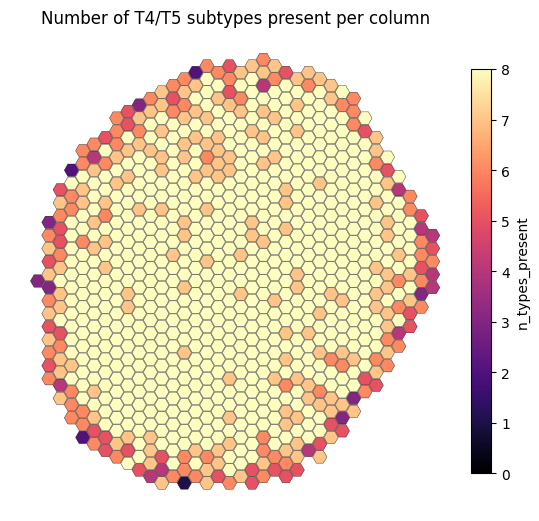

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
import matplotlib as mpl

def plot_n_subtypes_per_column(
    column_summary,
    value_col="n_types_present",
    hexsize=1.0,
    rotate=-np.pi/6,
    cmap="viridis",
    vmin=0,
    vmax=8,
    title="T4/T5 subtype coverage per column",
    label_cols=False,
    mirror_y = True,
    ax=None,
):
    df = column_summary.copy()

    df = df.dropna(subset=["p", "q", value_col]).copy()

    x, y = pq_to_xy(
        df["p"].to_numpy(),
        df["q"].to_numpy(),
        hexsize=hexsize,
        rotate=rotate,
    )

    df["x_plot"] = x
    df["y_plot"] = y
    
    if mirror_y:
        print("flipping y")
        df["y_plot"] = -df["y_plot"]
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    else:
        fig = ax.figure

    patches = []
    values = []

    for _, row in df.iterrows():
        patches.append(
            RegularPolygon(
                (row["x_plot"], row["y_plot"]),
                numVertices=6,
                radius=hexsize * 0.95,
                orientation=np.pi / 6,
            )
        )
        values.append(row[value_col])

    norm = Normalize(vmin=vmin, vmax=vmax)

    collection = PatchCollection(
        patches,
        cmap=cmap,
        norm=norm,
        edgecolor="k",
        linewidth=0.25,
    )
    collection.set_array(np.asarray(values))
    ax.add_collection(collection)

    if label_cols:
        for _, row in df.iterrows():
            if row["missing_types"] == "":
                continue
            ax.text(
                row["x_plot"],
                row["y_plot"],
                row["missing_types"],
                ha="center",
                va="center",
                fontsize=6,
                color="k",
                rotation=0,
            )
            
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.axis("off")
    ax.set_title(title)

    cbar = fig.colorbar(
        collection,
        ax=ax,
        shrink=0.75,
        pad=0.02,
    )
    cbar.set_label(value_col)
    cbar.set_ticks(np.arange(vmin, vmax + 1))

    return fig, ax
fig, ax = plt.subplots(figsize=(7, 7))
fig, _ = plot_n_subtypes_per_column(
    column_summary,
    value_col="n_types_present",
    cmap="magma",
    vmin=0,
    vmax=8,
    title="Number of T4/T5 subtypes present per column",
    label_cols=False,
    mirror_y=True,
    ax=ax,
)
plt.show()

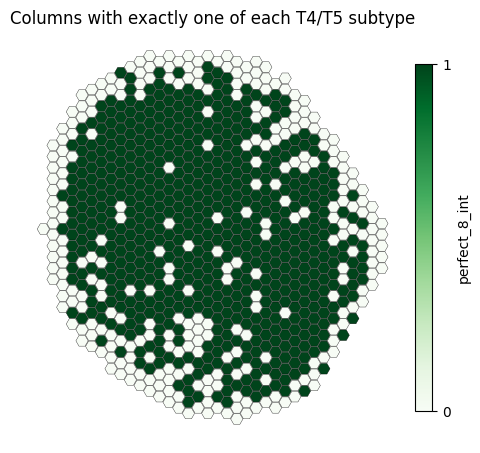

In [16]:
column_summary["perfect_8_int"] = column_summary["perfect_8"].astype(int)

fig, ax = plot_n_subtypes_per_column(
    column_summary,
    value_col="perfect_8_int",
    cmap="Greens",
    vmin=0,
    vmax=1,
    title="Columns with exactly one of each T4/T5 subtype",
)
plt.show()